/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_41472/1208658418.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.06, 1, 0.96])


Saved WAVES fig: WAVES_FIGS/waves_waves_only.png


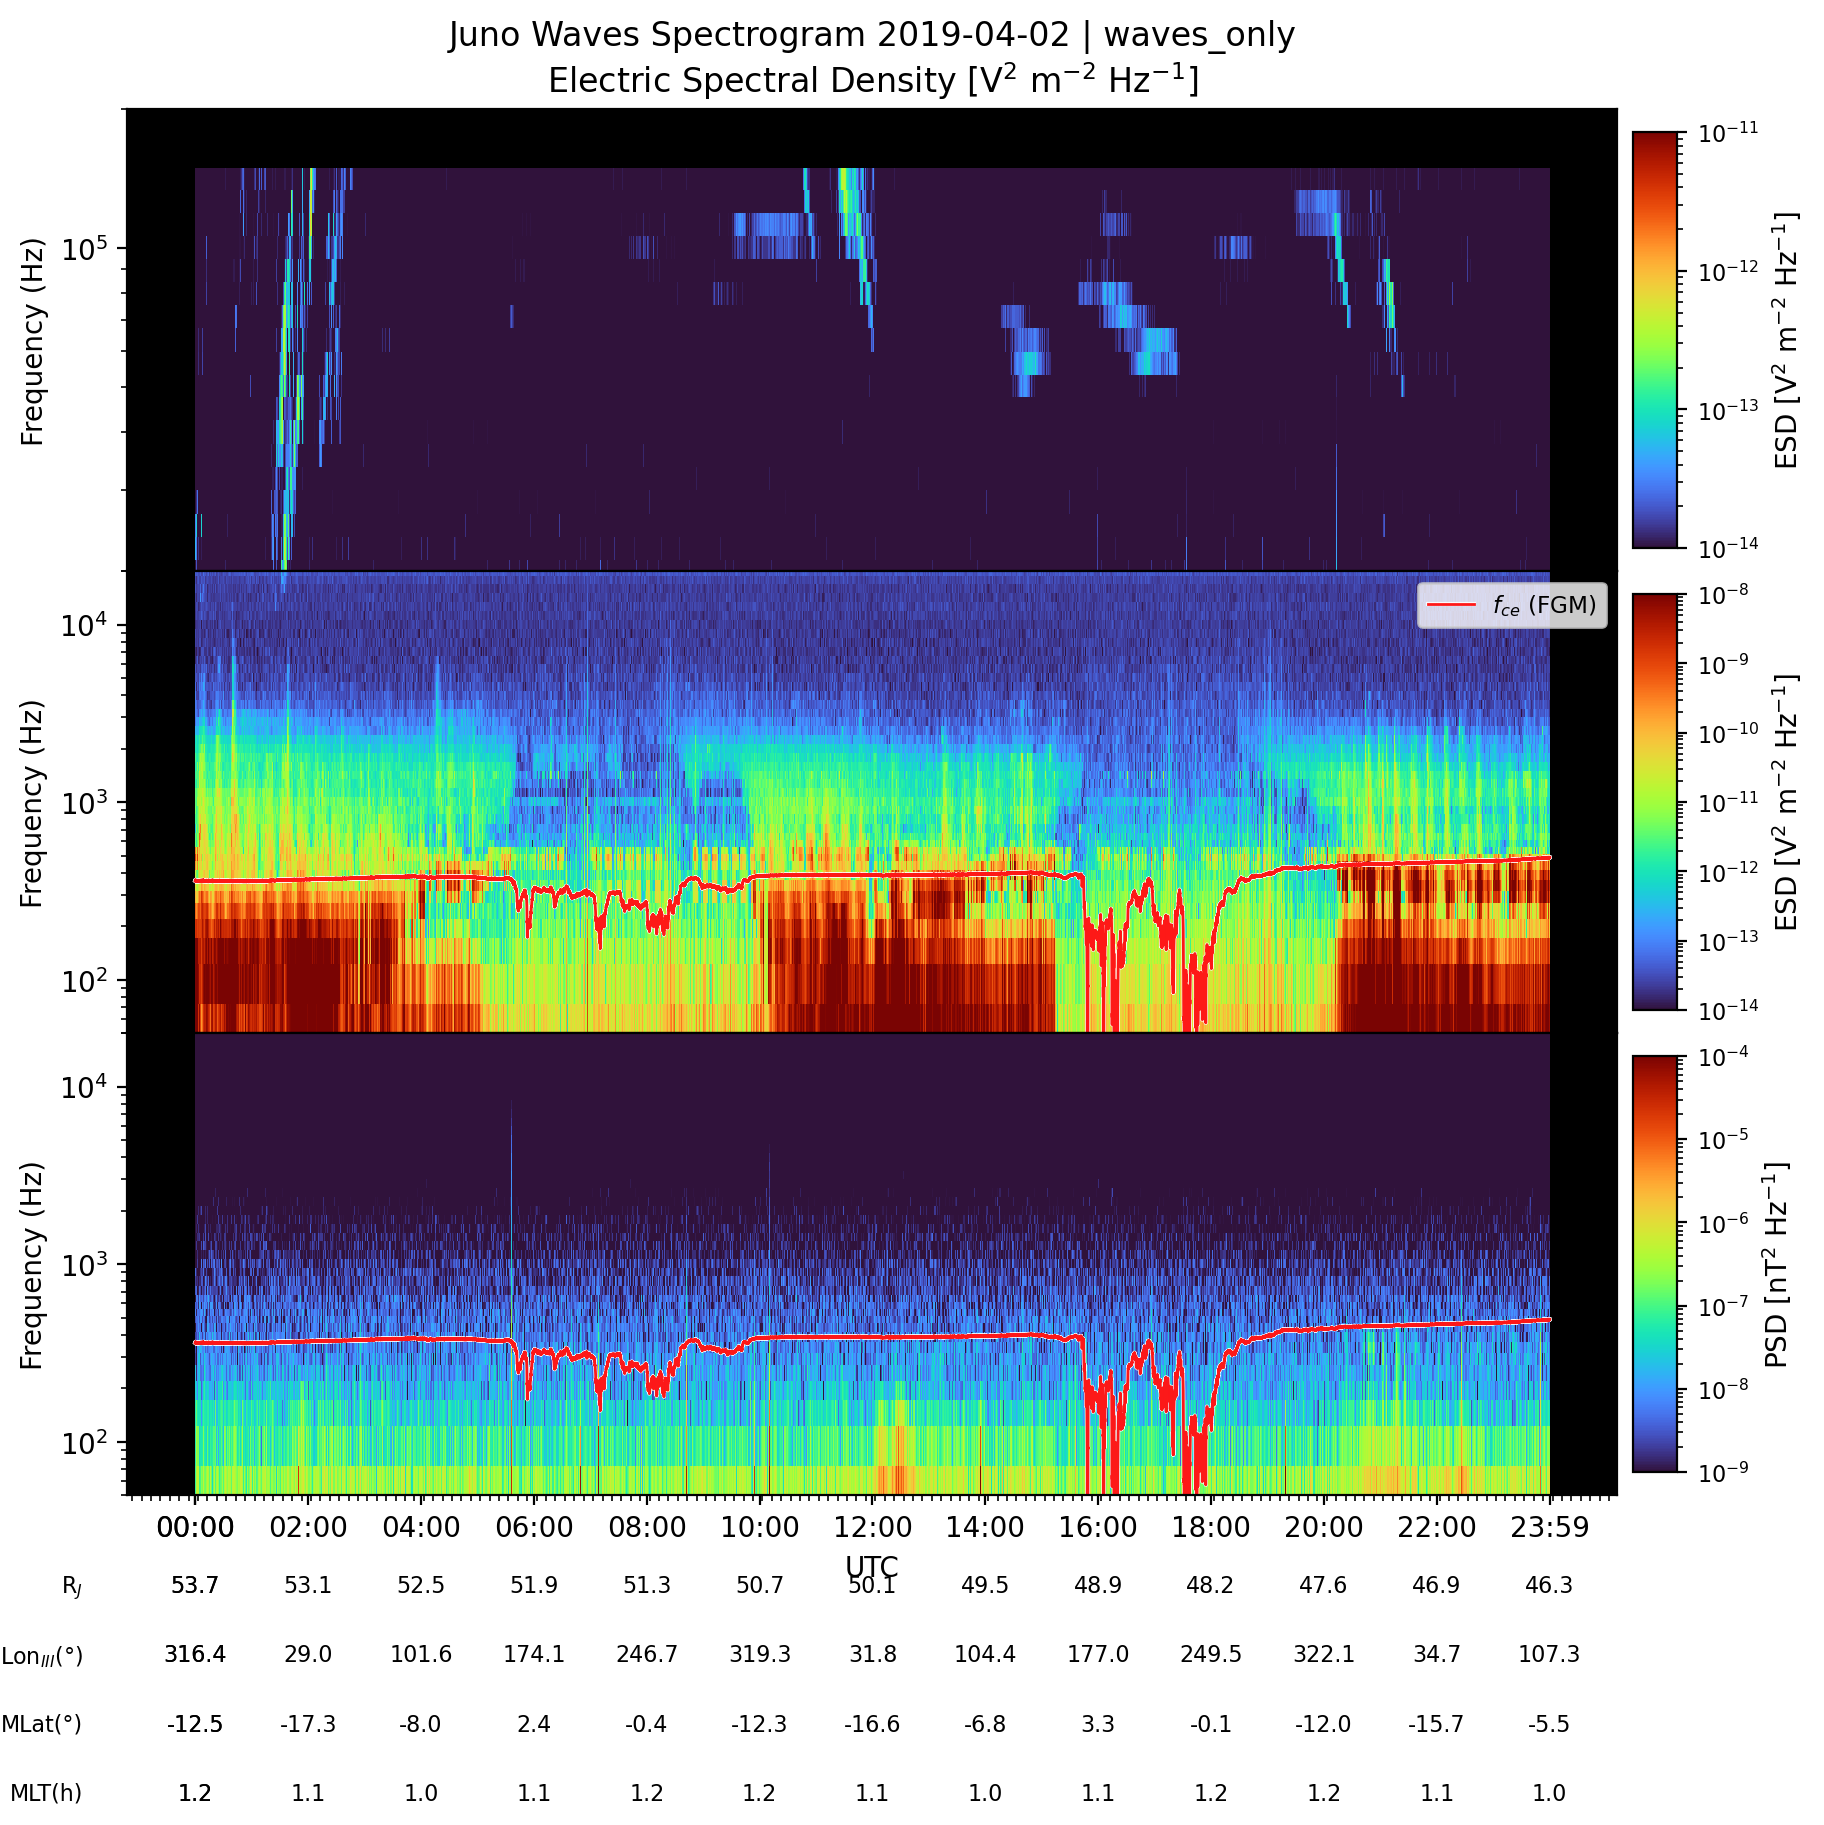

In [4]:
"""
WAVES-only segment analysis (LFRH + LHRL + optional MAG) with:
  - LFRH spectrogram
  - LHRL spectrogram
  - optional magnetic spectrogram (b=True)
  - overlays: f_pe (input), optional f_ce (FGM via EFC)
  - ephemeris rows

Dependencies:
  conda install -c dasdevelopers das2py
  pip install matplotlib pandas numpy
"""

import os
import numpy as np
from das2 import get_source
import das2
import matplotlib.pyplot as plt


# ──────────────────────────────────────────────────────────────────────────────
# GLOBAL CONFIG
# ──────────────────────────────────────────────────────────────────────────────
WAVES_FIG_OUTDIR = "WAVES_FIGS"
os.makedirs(WAVES_FIG_OUTDIR, exist_ok=True)

SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
SERVER_URL_EFC   = "tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2"
SERVER_URL_EPH   = "tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2"

LFRH_YLIM   = (2e4, 2e5)
LHRL_YLIM   = (5e1, 2e4)
B_YLIM      = (5e1, 2e4)

LFRH_LOGNORM = (1e-14, 1e-11)
LHRL_LOGNORM = (1e-14, 1e-8)
B_LOGNORM    = (1e-9, 1e-4)

OVERLAY_LW    = 1.0
OVERLAY_ALPHA = 0.9
PLOT_FCE_FZ_FUHR = True


# ──────────────────────────────────────────────────────────────────────────────
# WAVES MAIN
# ──────────────────────────────────────────────────────────────────────────────
def make_waves_segment(
    start_time,
    end_time,
    server_url=SERVER_URL_WAVES,
    label="segment",
    outdir=WAVES_FIG_OUTDIR,
    save_fig=True,
    show_fig=True,
    overlay_lw=OVERLAY_LW,
    overlay_alpha=OVERLAY_ALPHA,
    plot_fce_fz_fuhr=PLOT_FCE_FZ_FUHR,
    lfrh_ylim=LFRH_YLIM,
    lhrl_ylim=LHRL_YLIM,
    lfrh_lognorm=LFRH_LOGNORM,
    lhrl_lognorm=LHRL_LOGNORM,
    plot_b_panel=True,
    b_ylim=B_YLIM,
    b_lognorm=B_LOGNORM,
):
    import numpy as np
    import pandas as pd
    import matplotlib.dates as mdates
    import matplotlib.patheffects as pe
    from matplotlib.colors import LogNorm
    from matplotlib.gridspec import GridSpec
    from matplotlib.ticker import FixedLocator

    # Fetch WAVES
    source = get_source(server_url)
    ds = source.get({'time': (start_time, end_time)})
    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2 (whistler + middle).")
    whis, middle = ds[0], ds[1]

    def extract_arrays(d):
        f_arr = d['frequency']['center'].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

        t_arr = d['Time']['center'].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

        spec = d['spec_dens']['center'].array.squeeze()
        if spec.ndim != 2:
            raise ValueError(f"spec_dens not 2D after squeeze; got shape {spec.shape}")
        if spec.shape[1] != freqs.size:
            spec = spec.T

        return (
            np.array(times, dtype='datetime64[ms]'),
            np.asarray(freqs, float),
            np.asarray(spec, float),
        )

    times_lhrl, freqs_lhrl, spec_lhrl = extract_arrays(whis)
    times_lfrh, freqs_lfrh, spec_lfrh = extract_arrays(middle)

    def sanitize_linear(a):
        a = np.asarray(a, float).copy()
        a[~np.isfinite(a)] = np.nan
        a[a <= 0] = np.nan
        return a

    spec_lhrl_plot = sanitize_linear(spec_lhrl)
    spec_lfrh_plot = sanitize_linear(spec_lfrh)

    # MAG (b=True)
    times_b = freqs_b = spec_b = None
    spec_b_plot = None
    if plot_b_panel:
        try:
            ds_b = source.get({'time': (start_time, end_time), 'b': True})
            if len(ds_b) < 1:
                print("No magnetic dataset returned for b=True; skipping B panel.")
                plot_b_panel = False
            else:
                times_b, freqs_b, spec_b = extract_arrays(ds_b[0])
                spec_b_plot = sanitize_linear(spec_b)
        except Exception as e:
            print(f"Failed to retrieve magnetic dataset (b=True): {e}")
            plot_b_panel = False

    # Use LHRL cadence/time for ephemeris sampling
    eph_times = times_lhrl
    t0 = eph_times[0]
    t_sec = (eph_times - t0) / np.timedelta64(1, "s")
    dtcad = float(np.nanmedian(np.diff(t_sec)))
    if not np.isfinite(dtcad) or dtcad <= 0:
        dtcad = 1.0

    # ──────────────────────────────────────────────────────────
    # FIGURE LAYOUT
    # ──────────────────────────────────────────────────────────
    nrows = 3 if plot_b_panel else 2
    fig_h = 9 if plot_b_panel else 7

    fig = plt.figure(figsize=(10, fig_h), dpi=200)
    gs = GridSpec(
        nrows, 2, figure=fig,
        width_ratios=[1, 0.03],
        height_ratios=[1] * nrows,
        wspace=0.02, hspace=0.00
    )

    ax_lfrh = fig.add_subplot(gs[0, 0])
    ax_lhrl = fig.add_subplot(gs[1, 0], sharex=ax_lfrh)
    cax_lfrh = fig.add_subplot(gs[0, 1])
    cax_lhrl = fig.add_subplot(gs[1, 1])

    if plot_b_panel:
        ax_bsp = fig.add_subplot(gs[2, 0], sharex=ax_lfrh)
        cax_b  = fig.add_subplot(gs[2, 1])
        bottom_ax = ax_bsp
    else:
        ax_bsp = None
        cax_b = None
        bottom_ax = ax_lhrl

    def shrink_cax(cax, frac=0.90):
        pos = cax.get_position()
        new_h = pos.height * frac
        new_y = pos.y0 + (pos.height - new_h) / 2
        cax.set_position([pos.x0, new_y, pos.width, new_h])

    # LFRH spectrogram
    vmin_mid, vmax_mid = lfrh_lognorm
    im_lfrh = ax_lfrh.pcolormesh(
        times_lfrh, freqs_lfrh, spec_lfrh_plot.T,
        norm=LogNorm(vmin=vmin_mid, vmax=vmax_mid),
        cmap="turbo", shading="nearest"
    )
    ax_lfrh.set_ylim(*lfrh_ylim)
    ax_lfrh.set_yscale("log")
    ax_lfrh.set_facecolor("black")
    ax_lfrh.set_ylabel("Frequency (Hz)")
    ax_lfrh.tick_params(labelbottom=False)

    cb = fig.colorbar(im_lfrh, cax=cax_lfrh)
    cb.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb.ax.tick_params(labelsize=8)
    shrink_cax(cax_lfrh, 0.90)

    # LHRL spectrogram
    vmin_wh, vmax_wh = lhrl_lognorm
    im_lhrl = ax_lhrl.pcolormesh(
        times_lhrl, freqs_lhrl, spec_lhrl_plot.T,
        norm=LogNorm(vmin=vmin_wh, vmax=vmax_wh),
        cmap="turbo", shading="nearest"
    )
    ax_lhrl.set_ylim(*lhrl_ylim)
    ax_lhrl.set_yscale("log")
    ax_lhrl.set_facecolor("black")
    ax_lhrl.set_ylabel("Frequency (Hz)")
    ax_lhrl.tick_params(labelbottom=False)

    cb2 = fig.colorbar(im_lhrl, cax=cax_lhrl)
    cb2.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb2.ax.tick_params(labelsize=8)
    shrink_cax(cax_lhrl, 0.90)

    # MAG panel
    if plot_b_panel and (spec_b_plot is not None):
        vmin_b, vmax_b = b_lognorm
        im_b = ax_bsp.pcolormesh(
            times_b, freqs_b, spec_b_plot.T,
            norm=LogNorm(vmin=vmin_b, vmax=vmax_b),
            cmap="turbo", shading="nearest"
        )
        ax_bsp.set_ylim(*b_ylim)
        ax_bsp.set_yscale("log")
        ax_bsp.set_facecolor("black")
        ax_bsp.set_ylabel("Frequency (Hz)")

        cb3 = fig.colorbar(im_b, cax=cax_b)
        cb3.set_label(r'PSD [nT$^2$ Hz$^{-1}$]')
        cb3.ax.tick_params(labelsize=8)
        shrink_cax(cax_b, 0.90)
    elif plot_b_panel:
        ax_bsp.axis("off")
        cax_b.axis("off")

    for ax in [ax_lfrh, ax_lhrl]:
        ax.tick_params(axis="x", which="both", bottom=False, top=False,
                       labelbottom=False, labeltop=False)

    # Title
    ax_lfrh.set_title(
        f"Juno Waves Spectrogram {pd.to_datetime(start_time).strftime('%Y-%m-%d')} | {label}\n"
        r"Electric Spectral Density [V$^2$ m$^{-2}$ Hz$^{-1}$]"
    )

    # ──────────────────────────────────────────────────────────
    # Overlays f_pe (+ optional f_ce)
    # ──────────────────────────────────────────────────────────
    axes_for_overlays = [ax_lfrh, ax_lhrl]
    if plot_b_panel and ax_bsp is not None and ax_bsp.axison:
        axes_for_overlays.append(ax_bsp)


    if plot_fce_fz_fuhr:
        efc_source = das2.get_source(SERVER_URL_EFC)
        ds_efc = efc_source.get({"time": (start_time, end_time)})[0]
        efc_freq = np.asarray(ds_efc["fce"]["center"].array, float)
        efc_time = np.array(ds_efc["time"]["center"].array, dtype="datetime64[ms]")

        mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                efc_time[mask_fce], efc_freq[mask_fce],
                color="red", linewidth=overlay_lw, alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{ce}$ (FGM)" if ax_ov is ax_lhrl else None
            )

    ax_lhrl.legend(loc="upper right", frameon=True, ncols=2, fontsize="small")

    # ──────────────────────────────────────────────────────────
    # Bottom x-axis formatting
    # ──────────────────────────────────────────────────────────
    total_hours = (eph_times[-1] - eph_times[0]) / np.timedelta64(1, "h")
    tick_interval_h = 1 if total_hours <= 12 else 2

    major = mdates.HourLocator(interval=tick_interval_h)
    minor = mdates.MinuteLocator(interval=10)
    fmt   = mdates.DateFormatter("%H:%M")

    bottom_ax.xaxis.set_major_locator(major)
    bottom_ax.xaxis.set_minor_locator(minor)
    bottom_ax.xaxis.set_major_formatter(fmt)
    bottom_ax.set_xlabel("UTC")

    # ──────────────────────────────────────────────────────────
    # Ephemeris rows
    # ──────────────────────────────────────────────────────────
    t0h = eph_times[0].astype("datetime64[h]")
    t1h = eph_times[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
    maj = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, "h"))
    all_ticks = np.unique(np.concatenate(([eph_times[0]], maj, [eph_times[-1]])))

    py_ticks = [t.tolist() for t in all_ticks]
    all_tick_nums = mdates.date2num(py_ticks)

    bottom_ax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
    bottom_ax.xaxis.set_major_formatter(fmt)

    eph_src = get_source(SERVER_URL_EPH)
    ds_eph  = eph_src.get({"time": (start_time, end_time, int(max(1, round(dtcad))))})[0]

    rad   = ds_eph["radius"]["center"].array
    lon3  = ds_eph["long"]["center"].array
    mlatE = ds_eph["mlat"]["center"].array
    mltE  = ds_eph["mlt"]["center"].array
    if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
        mltE = (mltE / np.timedelta64(1, "h")).astype(float)

    eph_time_arr = ds_eph["time"]["center"].array
    eph_time_arr = np.array(eph_time_arr, dtype="datetime64[ms]")
    if getattr(eph_time_arr, "ndim", 1) > 1:
        eph_time_arr = eph_time_arr[:, 0]

    idx_eph = [np.argmin(np.abs(eph_time_arr - mt)) for mt in all_ticks]

    row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
    row_arrays  = [rad, lon3, mlatE, mltE]
    row_spacing = 0.15

    for j, (lab, arr) in enumerate(zip(row_lbls, row_arrays)):
        off = -row_spacing * (j + 1)
        sax = bottom_ax.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
        sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
        vals = np.asarray(arr)[idx_eph]
        sax.set_xticklabels([f"{v:.1f}" for v in vals], rotation=0, va="top", fontsize=8)
        sax.spines["bottom"].set_visible(False)
        sax.tick_params(axis="x", length=0)
        sax.xaxis.set_ticks_position("bottom")
        sax.xaxis.set_label_position("bottom")
        txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
        txt.set_x(-0.03)
        txt.set_ha("right")

    fig.tight_layout(rect=[0, 0.06, 1, 0.96])

    if save_fig:
        os.makedirs(outdir, exist_ok=True)
        safe_label = label if label else "segment"
        fname = os.path.join(outdir, f"waves_{safe_label}.png")
        fig.savefig(fname, dpi=300)
        print(f"Saved WAVES fig: {fname}")

    if show_fig:
        plt.show()
    else:
        plt.close(fig)

    return {
        "times_lhrl": times_lhrl,
        "freqs_lhrl": freqs_lhrl,
        "spec_lhrl": spec_lhrl,
        "times_lfrh": times_lfrh,
        "freqs_lfrh": freqs_lfrh,
        "spec_lfrh": spec_lfrh,
        "times_b": times_b,
        "freqs_b": freqs_b,
        "spec_b": spec_b,
    }


# ──────────────────────────────────────────────────────────────
# MINIMAL TEST HARNESS
# ──────────────────────────────────────────────────────────────
if __name__ == "__main__":
    start_iso = "2019-04-02T00:00:00"
    end_iso   = "2019-04-03T00:00:00"



    make_waves_segment(
        start_time=start_iso,
        end_time=end_iso,
        label="waves_only",
        save_fig=True,
        show_fig=True,
    )

/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_30808/1208658418.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.06, 1, 0.96])


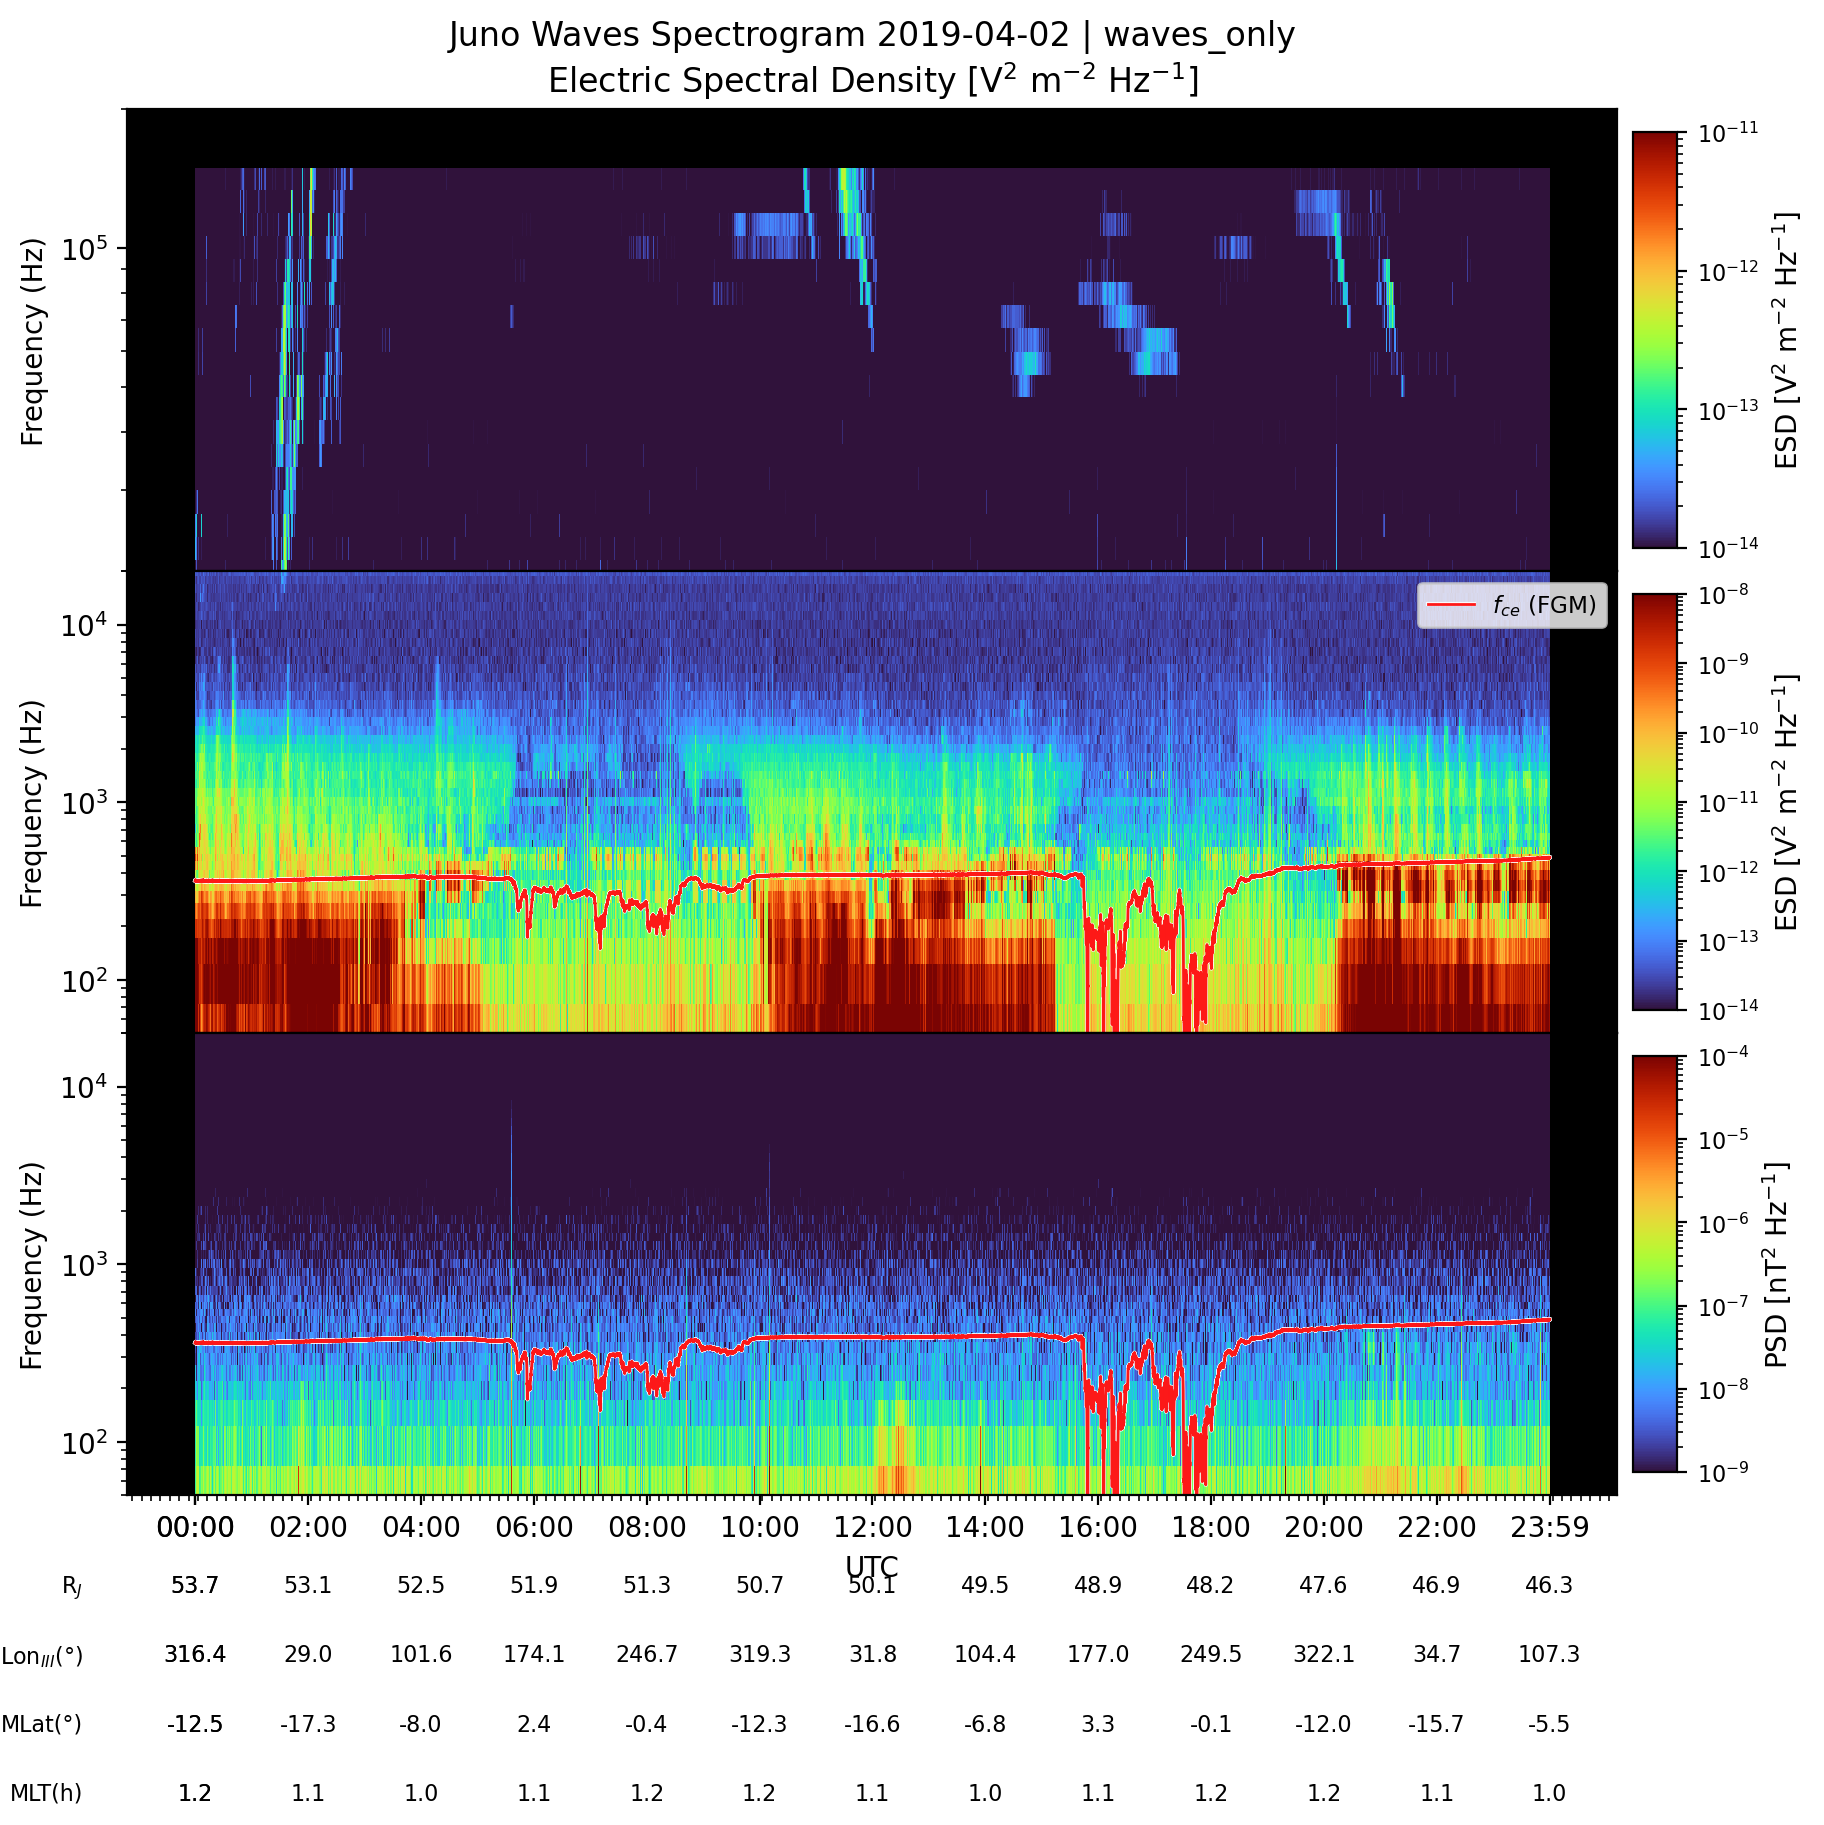

In [39]:
waves = make_waves_segment(
    start_time="2019-04-02T00:00:00",
    end_time="2019-04-03T00:00:00",
    label="waves_only",
    save_fig=False,
    show_fig=True,
)

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pywt
from matplotlib.colors import LogNorm


def sweep_lhrl_rows_cwt_for_xray_period(
    times_lhrl,
    freqs_lhrl,
    spec_lhrl,
    target_period_min=(1.0, 15.0),
    wavelet="cmor1.5-1.0",
    n_periods=96,
    period_pad_factor=1.5,
    detrend_window_min=20.0,
    min_finite_frac=0.7,
    statistic="max",
    make_plots=True,
    top_n=5,
):
    """
    Run a row-by-row CWT search on the LHRL spectrogram.

    Each frequency row is treated as a 1D time series:
        y_i(t) = ESD(t, f_i)

    Parameters
    ----------
    times_lhrl : array-like
        datetime64 time array
    freqs_lhrl : array-like
        frequency array in Hz
    spec_lhrl : 2D array
        spectrogram, shape (Nt, Nf) preferred
    target_period_min : tuple
        target period range in minutes
    wavelet : str
        PyWavelets wavelet name
    n_periods : int
        number of sampled periods
    period_pad_factor : float
        expands transform range around target band
    detrend_window_min : float
        smoothing window for detrending
    min_finite_frac : float
        minimum finite fraction required
    statistic : str
        one of {"max", "mean", "sum"}
    make_plots : bool
        whether to plot outputs
    top_n : int
        number of top rows to report
    """

    times = np.asarray(times_lhrl)
    freqs = np.asarray(freqs_lhrl, dtype=float)
    spec = np.asarray(spec_lhrl, dtype=float)

    if spec.ndim != 2:
        raise ValueError(f"spec_lhrl must be 2D; got {spec.shape}")

    # Ensure shape = (Nt, Nf)
    if spec.shape[0] != times.size and spec.shape[1] == times.size:
        spec = spec.T

    if spec.shape[0] != times.size:
        raise ValueError("spec first dimension must match times")
    if spec.shape[1] != freqs.size:
        raise ValueError("spec second dimension must match freqs")

    # Clean data
    spec = spec.copy()
    spec[~np.isfinite(spec)] = np.nan
    spec[spec <= 0] = np.nan

    # Time cadence
    t_sec = (times - times[0]) / np.timedelta64(1, "s")
    t_sec = np.asarray(t_sec, float)

    dt = float(np.nanmedian(np.diff(t_sec)))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Invalid cadence")

    # Period grid
    pmin_target, pmax_target = map(float, target_period_min)
    if pmin_target <= 0 or pmax_target <= pmin_target:
        raise ValueError("target_period_min must be (pmin, pmax) with pmin < pmax")

    pmin_full = pmin_target / period_pad_factor
    pmax_full = pmax_target * period_pad_factor

    periods_min = np.geomspace(pmin_full, pmax_full, int(n_periods))
    periods_sec = periods_min * 60.0
    freqs_hz = 1.0 / periods_sec

    fs = 1.0 / dt
    normalized_freqs = freqs_hz / fs
    scales = pywt.frequency2scale(wavelet, normalized_freqs)

    # Outputs
    n_freq = freqs.size
    n_time = times.size

    score_per_row = np.full(n_freq, np.nan)
    best_period_per_row = np.full(n_freq, np.nan)
    best_time_idx_per_row = np.full(n_freq, -1, dtype=int)
    band_power_map = np.full((n_freq, n_time), np.nan)

    row_series_store = []
    cwt_power_store = []
    cwt_period_store = []

    def fill_nan_1d(y):
        y = np.asarray(y, float)
        m = np.isfinite(y)
        if m.sum() < 2:
            return None
        x = np.arange(y.size)
        return np.interp(x, x[m], y[m])

    def smooth_boxcar(y, win_samples):
        if win_samples < 3:
            return np.full_like(y, np.nanmean(y))
        if win_samples % 2 == 0:
            win_samples += 1
        kernel = np.ones(win_samples, dtype=float) / win_samples
        return np.convolve(y, kernel, mode="same")

    detrend_window_samp = max(3, int(round((detrend_window_min * 60.0) / dt)))

    # ---- loop through ALL frequency rows ----
    for i, f0 in enumerate(freqs):
        y = spec[:, i]

        finite_frac = np.count_nonzero(np.isfinite(y)) / y.size
        if finite_frac < min_finite_frac:
            row_series_store.append(None)
            cwt_power_store.append(None)
            cwt_period_store.append(None)
            continue

        y_fill = fill_nan_1d(y)
        if y_fill is None:
            row_series_store.append(None)
            cwt_power_store.append(None)
            cwt_period_store.append(None)
            continue

        trend = smooth_boxcar(y_fill, detrend_window_samp)
        y_det = y_fill - trend

        sig = np.nanstd(y_det)
        if not np.isfinite(sig) or sig <= 0:
            row_series_store.append(None)
            cwt_power_store.append(None)
            cwt_period_store.append(None)
            continue

        y_use = y_det / sig

        coef, returned_freqs = pywt.cwt(
            y_use,
            scales,
            wavelet,
            sampling_period=dt,
            method="fft",
        )
        power = np.abs(coef) ** 2

        returned_periods_min = (1.0 / returned_freqs) / 60.0
        order = np.argsort(returned_periods_min)
        returned_periods_min = returned_periods_min[order]
        power = power[order, :]

        band = (returned_periods_min >= pmin_target) & (returned_periods_min <= pmax_target)
        if not np.any(band):
            row_series_store.append(y_use)
            cwt_power_store.append(power)
            cwt_period_store.append(returned_periods_min)
            continue

        band_power = power[band, :]
        band_power_map[i, :] = np.nanmax(band_power, axis=0)

        if statistic == "max":
            score = np.nanmax(band_power)
        elif statistic == "mean":
            score = np.nanmean(band_power)
        elif statistic == "sum":
            score = np.nansum(band_power)
        else:
            raise ValueError("statistic must be 'max', 'mean', or 'sum'")

        score_per_row[i] = score

        j_time = int(np.nanargmax(np.nanmax(band_power, axis=0)))
        best_time_idx_per_row[i] = j_time

        j_period_local = int(np.nanargmax(band_power[:, j_time]))
        best_period_per_row[i] = returned_periods_min[band][j_period_local]

        row_series_store.append(y_use)
        cwt_power_store.append(power)
        cwt_period_store.append(returned_periods_min)

    valid = np.isfinite(score_per_row)
    if not np.any(valid):
        raise RuntimeError("No valid frequency rows found")

    ranked_idx = np.argsort(score_per_row[valid])[::-1]
    valid_idx = np.where(valid)[0]
    ranked_rows = valid_idx[ranked_idx]

    best_idx = int(ranked_rows[0])
    best_freq = float(freqs[best_idx])
    best_time = times[best_time_idx_per_row[best_idx]]
    best_period = float(best_period_per_row[best_idx])

    top_candidates = []
    for idx in ranked_rows[:top_n]:
        top_candidates.append({
            "freq_hz": float(freqs[idx]),
            "score": float(score_per_row[idx]),
            "best_period_min": float(best_period_per_row[idx]),
            "best_time": times[best_time_idx_per_row[idx]],
        })

    result = {
        "times": times,
        "freqs_hz": freqs,
        "score_per_row": score_per_row,
        "best_period_per_row_min": best_period_per_row,
        "best_time_idx_per_row": best_time_idx_per_row,
        "band_power_map": band_power_map,
        "target_period_min": (pmin_target, pmax_target),
        "wavelet": wavelet,
        "dt_seconds": dt,
        "top_candidates": top_candidates,
        "best_row_index": best_idx,
        "best_freq_hz": best_freq,
        "best_time": best_time,
        "best_period_min": best_period,
        "best_timeseries": row_series_store[best_idx],
        "best_cwt_power": cwt_power_store[best_idx],
        "best_cwt_periods_min": cwt_period_store[best_idx],
    }

    if make_plots:
        fig, axes = plt.subplots(
            2, 1, figsize=(11, 8), dpi=160,
            gridspec_kw={"height_ratios": [1, 1], "hspace": 0.25}
        )

        ax0, ax1 = axes
        t_num = mdates.date2num([t.tolist() for t in times])

        extent = [t_num[0], t_num[-1], freqs[0], freqs[-1]]
        im0 = ax0.imshow(
            band_power_map,
            aspect="auto",
            origin="lower",
            extent=extent,
            interpolation="nearest", cmap='seismic', norm=LogNorm(vmin=0.1)
        )
        ax0.axhline(best_freq, color="white", ls="--", lw=1.2)
        ax0.axvline(mdates.date2num(best_time.tolist()), color="white", ls="--", lw=1.2)
        ax0.set_ylabel("LHRL frequency (Hz)")
        ax0.set_title(
            f"Row-by-row target-band CWT power | {pmin_target:.1f}–{pmax_target:.1f} min | best={best_freq:.0f} Hz at {best_period:.2f} min"
        )
        ax0.xaxis_date()
        ax0.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        plt.colorbar(im0, ax=ax0, label="Target-band wavelet power")

        best_power = result["best_cwt_power"]
        best_periods = result["best_cwt_periods_min"]
        im1 = ax1.imshow(
            best_power,
            aspect="auto",
            origin="lower",
            extent=[t_num[0], t_num[-1], best_periods[0], best_periods[-1]],
            interpolation="nearest", cmap='seismic', norm=LogNorm(vmin=0.1)
        )
        ax1.axhline(pmin_target, color="white", ls="--", lw=0.8)
        ax1.axhline(pmax_target, color="white", ls="--", lw=0.8)
        ax1.axhline(best_period, color="red", ls="--", lw=1.0)
        ax1.axvline(mdates.date2num(best_time.tolist()), color="white", ls="--", lw=1.0)
        ax1.set_ylabel("Period (min)")
        ax1.set_xlabel("UTC")
        ax1.set_title(f"Best-row CWT | {best_freq:.1f} Hz")
        ax1.xaxis_date()
        ax1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        plt.colorbar(im1, ax=ax1, label="Wavelet power")

        plt.show()

    return result

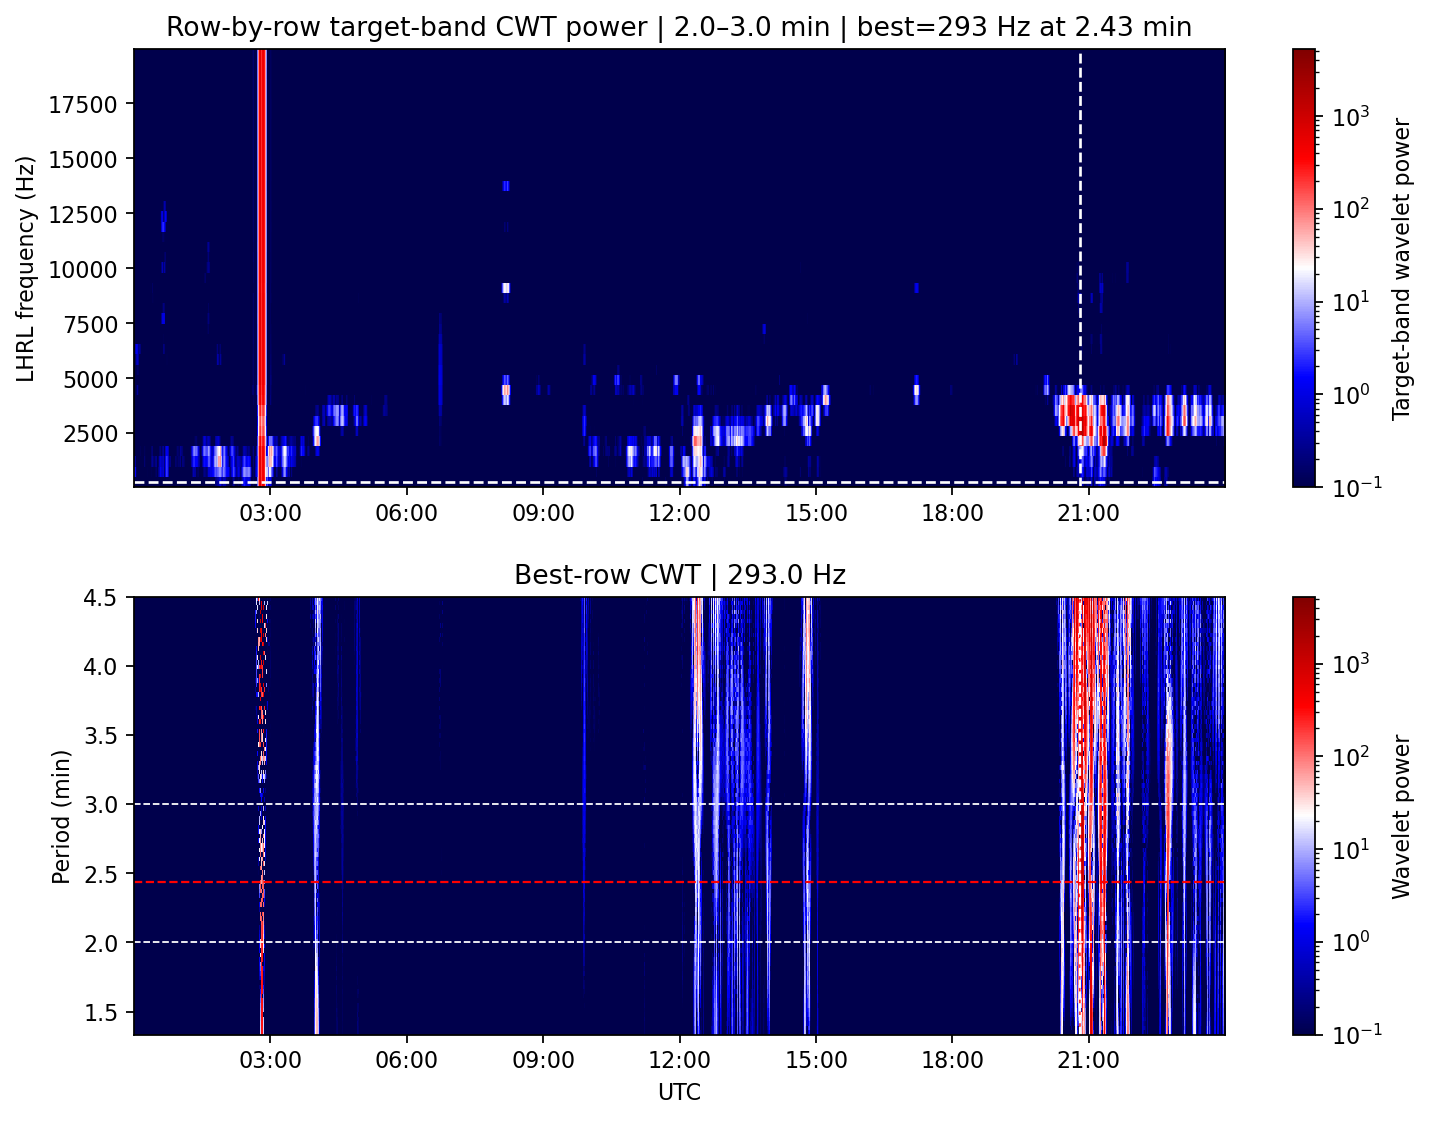

In [43]:
row_result = sweep_lhrl_rows_cwt_for_xray_period(
    times_lhrl=waves["times_lhrl"],
    freqs_lhrl=waves["freqs_lhrl"],
    spec_lhrl=waves["spec_lhrl"],
    target_period_min=(2.0, 3.0),
    wavelet="morl",
    statistic="max",
    make_plots=True,
    top_n=10,
)

/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_30808/2534138934.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


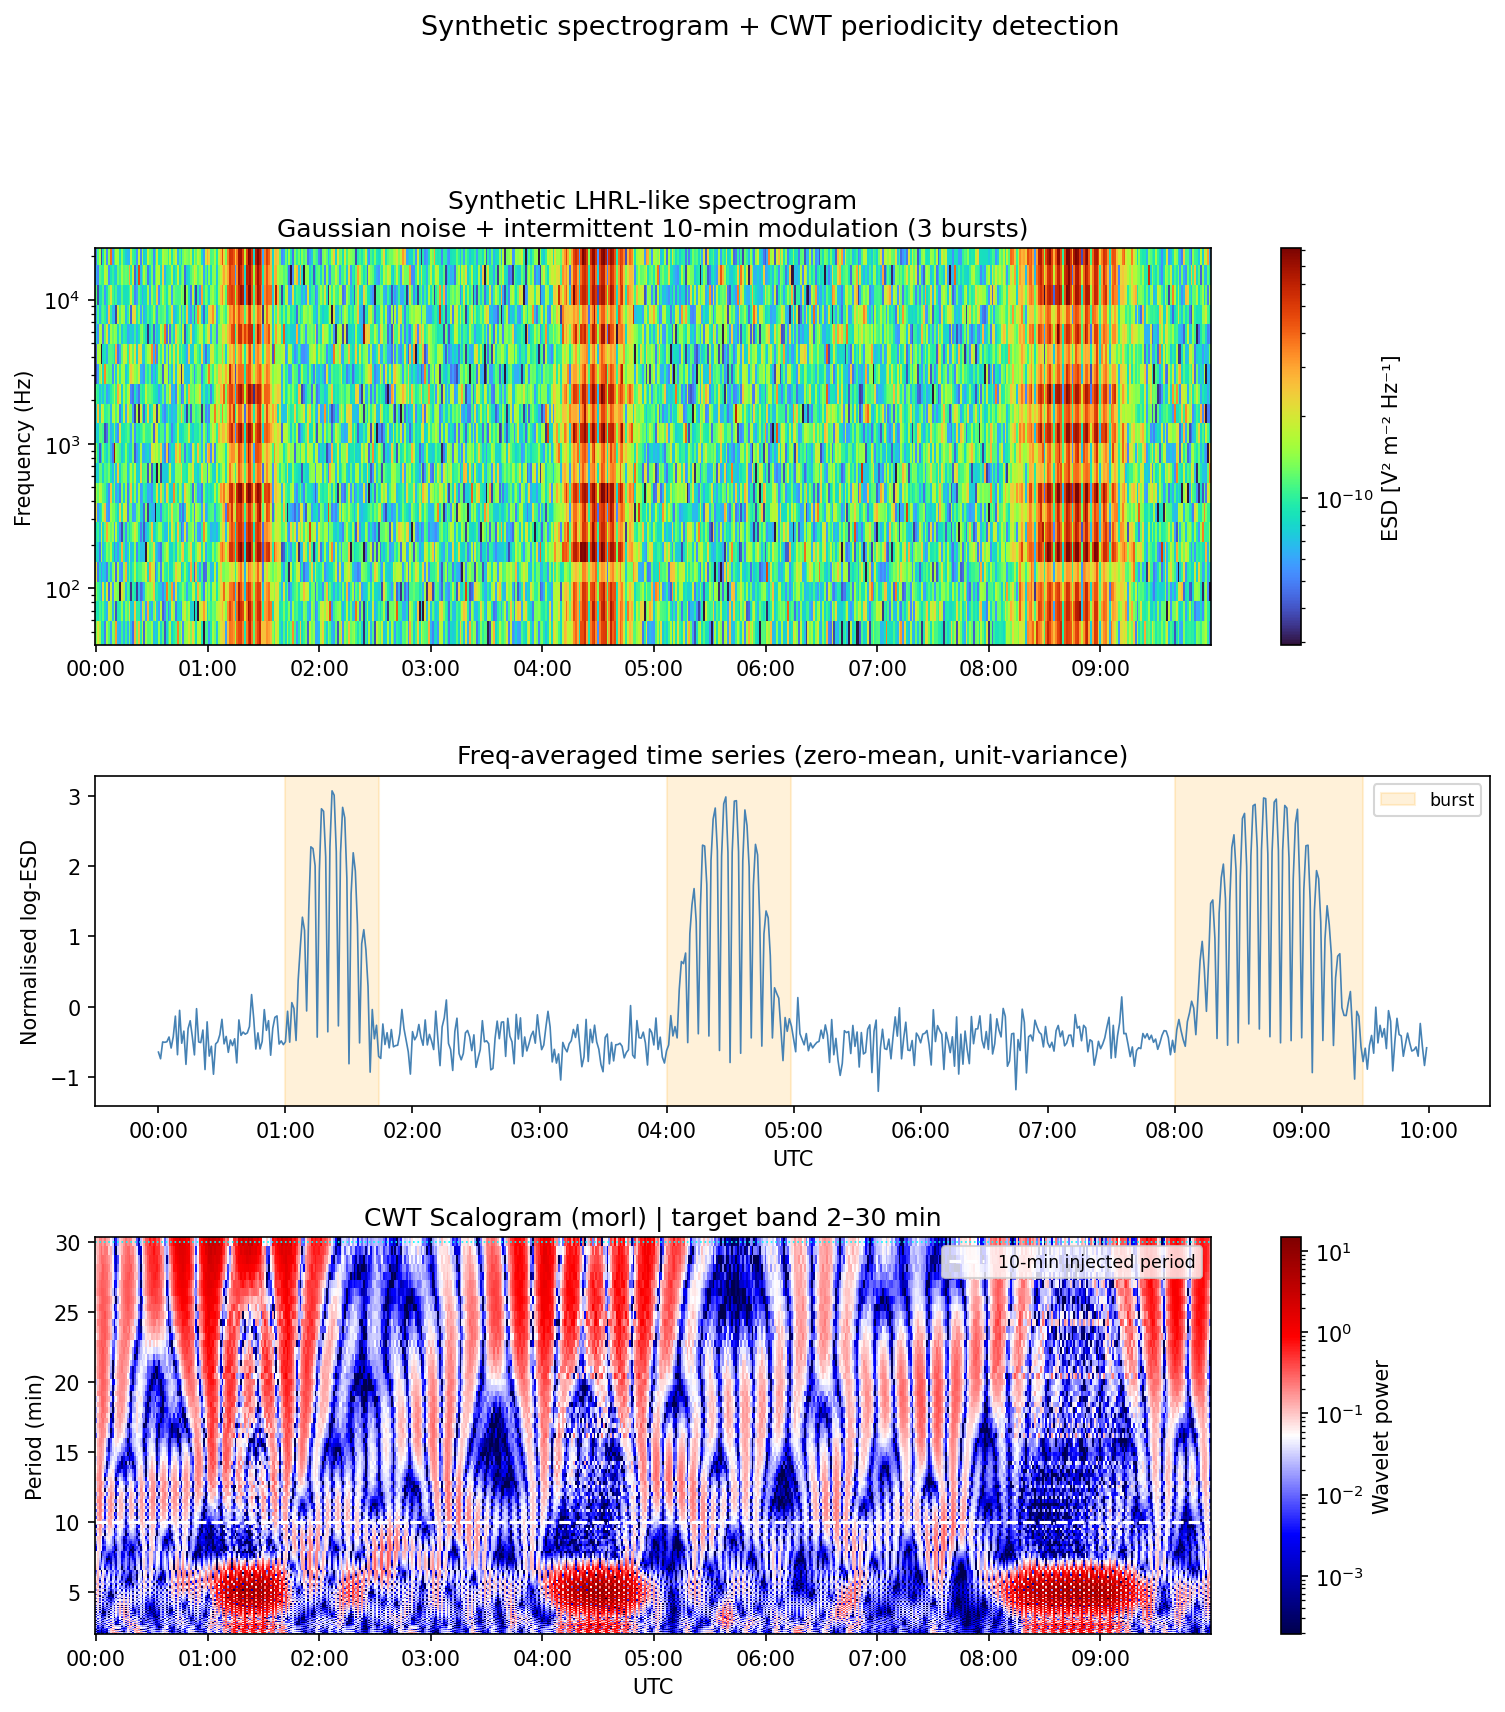

Injected period : 10.0 min
Detected period : 5.00 min
Peak power time : 04:30 UTC
Injected bin        : 9 (~854.1 Hz)
Injected period     : 10.0 min
Detected period(bin): 5.00 min
Peak power time     : 08:45 UTC


In [45]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pywt
from matplotlib.colors import LogNorm
from datetime import datetime, timedelta

# ── Synthetic spectrogram parameters ──────────────────────────────────────────
np.random.seed(42)
dt_sec      = 60.0          # 1-minute cadence
total_hours = 10.0
n_times     = int(total_hours * 3600 / dt_sec)   # 600 samples
n_freqs     = 20

t_sec  = np.arange(n_times) * dt_sec
t_base = np.datetime64("2019-04-02T00:00:00", "ms")
times  = t_base + (t_sec * 1e3).astype("timedelta64[ms]")

freqs_syn = np.geomspace(50, 20000, n_freqs)   # Hz (log-spaced, like LHRL)

# ── Gaussian noise base ────────────────────────────────────────────────────────
noise_floor = 1e-10
spec_syn = noise_floor * np.random.lognormal(mean=0.0, sigma=0.5,
                                              size=(n_times, n_freqs))

# ── Intermittent 10-minute period modulation ───────────────────────────────────
period_min   = 10.0
period_sec   = period_min * 60.0
mod_amp      = 5.0 * noise_floor

# Three separate bursts (start_min, duration_min)
bursts = [(60, 45), (240, 60), (480, 90)]

mod_signal = np.zeros(n_times)
for (t_start_min, dur_min) in bursts:
    i0 = int(t_start_min * 60 / dt_sec)
    i1 = int((t_start_min + dur_min) * 60 / dt_sec)
    i1 = min(i1, n_times)
    burst_t = t_sec[i0:i1] - t_sec[i0]
    # sinusoidal modulation with a Hann taper
    taper = np.hanning(i1 - i0)
    mod_signal[i0:i1] = mod_amp * taper * np.sin(2 * np.pi * burst_t / period_sec)

# Inject into all frequency rows with random frequency-dependent scaling
for fi in range(n_freqs):
    amp_scale = np.random.uniform(0.5, 1.5)
    spec_syn[:, fi] += np.abs(mod_signal) * amp_scale   # keep positive

spec_syn = np.clip(spec_syn, 1e-15, None)

# ── Plot synthetic spectrogram ─────────────────────────────────────────────────
t_num = mdates.date2num([t.tolist() for t in times])
fmt   = mdates.DateFormatter("%H:%M")

fig, axes = plt.subplots(3, 1, figsize=(12, 12), dpi=150,
                         gridspec_kw={"height_ratios": [1.2, 1, 1.2], "hspace": 0.35})

# Panel 0: synthetic spectrogram
ax0 = axes[0]
im0 = ax0.pcolormesh(
    times, freqs_syn, spec_syn.T,
    norm=LogNorm(vmin=spec_syn.min() * 2, vmax=spec_syn.max() * 0.8),
    cmap="turbo", shading="nearest"
)
ax0.set_yscale("log")
ax0.set_facecolor("black")
ax0.set_ylabel("Frequency (Hz)")
ax0.set_title("Synthetic LHRL-like spectrogram\n"
              "Gaussian noise + intermittent 10-min modulation (3 bursts)")
ax0.xaxis_date()
ax0.xaxis.set_major_formatter(fmt)
plt.colorbar(im0, ax=ax0, label=r"ESD [V² m⁻² Hz⁻¹]")

# ── CWT on frequency-averaged time series ─────────────────────────────────────
# Average across all frequency rows (log-mean)
log_mean_series = np.nanmean(np.log10(spec_syn), axis=1)
log_mean_series -= np.nanmean(log_mean_series)   # zero-mean
log_mean_series /= np.nanstd(log_mean_series)    # normalise

# Period grid for CWT
wavelet   = "morl"
pmin_min  = 2.0
pmax_min  = 30.0
n_periods = 128

periods_min = np.geomspace(pmin_min, pmax_min, n_periods)
periods_sec_grid = periods_min * 60.0
freqs_cwt_hz = 1.0 / periods_sec_grid

fs = 1.0 / dt_sec
norm_freqs = freqs_cwt_hz / fs
scales = pywt.frequency2scale(wavelet, norm_freqs)

coef, returned_freqs = pywt.cwt(
    log_mean_series, scales, wavelet,
    sampling_period=dt_sec, method="fft"
)
power = np.abs(coef) ** 2

returned_periods_min = (1.0 / returned_freqs) / 60.0
order = np.argsort(returned_periods_min)
returned_periods_min = returned_periods_min[order]
power = power[order, :]

# Panel 1: normalised time series
ax1 = axes[1]
ax1.plot(times, log_mean_series, color="steelblue", lw=0.8)
for (t_start_min, dur_min) in bursts:
    i0 = int(t_start_min * 60 / dt_sec)
    i1 = min(int((t_start_min + dur_min) * 60 / dt_sec), n_times)
    ax1.axvspan(times[i0].tolist(), times[i1 - 1].tolist(),
                alpha=0.15, color="orange", label="burst" if i0 == int(60*60/dt_sec) else None)
ax1.set_ylabel("Normalised log-ESD")
ax1.set_xlabel("UTC")
ax1.set_title("Freq-averaged time series (zero-mean, unit-variance)")
ax1.xaxis_date()
ax1.xaxis.set_major_formatter(fmt)
ax1.legend(loc="upper right", fontsize="small")

# Panel 2: CWT scalogram
ax2 = axes[2]
im2 = ax2.pcolormesh(
    t_num, returned_periods_min, power,
    norm=LogNorm(vmin=np.nanpercentile(power, 5)),
    cmap="seismic", shading="nearest"
)
ax2.axhline(period_min, color="white", ls="--", lw=1.5, label=f"{period_min:.0f}-min injected period")
ax2.axhline(pmin_min,   color="cyan",  ls=":",  lw=0.8)
ax2.axhline(pmax_min,   color="cyan",  ls=":",  lw=0.8)
ax2.set_ylabel("Period (min)")
ax2.set_xlabel("UTC")
ax2.set_title(f"CWT Scalogram ({wavelet}) | target band {pmin_min:.0f}–{pmax_min:.0f} min")
ax2.xaxis_date()
ax2.xaxis.set_major_formatter(fmt)
ax2.legend(loc="upper right", fontsize="small")
plt.colorbar(im2, ax=ax2, label="Wavelet power")

plt.suptitle("Synthetic spectrogram + CWT periodicity detection", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# ── Summary ───────────────────────────────────────────────────────────────────
peak_period_idx  = np.unravel_index(np.nanargmax(power), power.shape)
detected_period  = returned_periods_min[peak_period_idx[0]]
detected_time_num = t_num[peak_period_idx[1]]
detected_time     = mdates.num2date(detected_time_num)

print(f"Injected period : {period_min:.1f} min")
print(f"Detected period : {detected_period:.2f} min")
print(f"Peak power time : {detected_time.strftime('%H:%M')} UTC")
# Rebuild synthetic spectrogram with modulation injected into a single frequency bin
np.random.seed(42)
spec_syn_bin = noise_floor * np.random.lognormal(mean=0.0, sigma=0.5, size=(n_times, n_freqs))

mod_signal_bin = np.zeros(n_times)
for (t_start_min, dur_min) in bursts:
    i0 = int(t_start_min * 60 / dt_sec)
    i1 = min(int((t_start_min + dur_min) * 60 / dt_sec), n_times)
    burst_t = t_sec[i0:i1] - t_sec[i0]
    taper = np.hanning(i1 - i0)
    mod_signal_bin[i0:i1] = mod_amp * taper * np.sin(2 * np.pi * burst_t / period_sec)

# Inject into one frequency bin only
target_freq_hz = 1000.0
bin_idx = int(np.argmin(np.abs(freqs_syn - target_freq_hz)))
spec_syn_bin[:, bin_idx] += np.abs(mod_signal_bin)
spec_syn_bin = np.clip(spec_syn_bin, 1e-15, None)

# CWT on that single-bin time series
single_bin_series = np.log10(spec_syn_bin[:, bin_idx])
single_bin_series -= np.nanmean(single_bin_series)
single_bin_series /= np.nanstd(single_bin_series)

coef_bin, returned_freqs_bin = pywt.cwt(
    single_bin_series, scales, wavelet, sampling_period=dt_sec, method="fft"
)
power_bin = np.abs(coef_bin) ** 2
returned_periods_min_bin = (1.0 / returned_freqs_bin) / 60.0
order_bin = np.argsort(returned_periods_min_bin)
returned_periods_min_bin = returned_periods_min_bin[order_bin]
power_bin = power_bin[order_bin, :]

# Quick check
peak_idx_bin = np.unravel_index(np.nanargmax(power_bin), power_bin.shape)
detected_period_bin = returned_periods_min_bin[peak_idx_bin[0]]
detected_time_bin = mdates.num2date(t_num[peak_idx_bin[1]])

print(f"Injected bin        : {bin_idx} (~{freqs_syn[bin_idx]:.1f} Hz)")
print(f"Injected period     : {period_min:.1f} min")
print(f"Detected period(bin): {detected_period_bin:.2f} min")
print(f"Peak power time     : {detected_time_bin.strftime('%H:%M')} UTC")

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt


def plot_summed_frequency_bins_fft(
    times,
    freqs,
    spec,
    rows_per_bin=4,
    period_min_min=1,
    period_max_min=15,
    outdir="WAVES_FIGS/bin_fft_plots",
    prefix="lhrl",
    save_fig=True,
    show_fig=True,
    detrend=True,
):
    """
    For a spectrogram with shape (ntime, nfreq), sum together frequency rows
    in groups of `rows_per_bin`, then for each summed band create a small
    2-panel figure:
      - top: summed line vs time
      - bottom: FFT power vs period (minutes), limited to 1-15 min

    Parameters
    ----------
    times : array-like of datetime64
        Time array of length ntime.
    freqs : array-like
        Frequency array of length nfreq.
    spec : 2D array
        Spectrogram with shape (ntime, nfreq).
    rows_per_bin : int
        Number of adjacent frequency rows to sum together.
    period_min_min : float
        Minimum period to show in minutes.
    period_max_min : float
        Maximum period to show in minutes.
    outdir : str
        Output folder.
    prefix : str
        Prefix for saved filenames.
    save_fig : bool
        Whether to save each figure.
    show_fig : bool
        Whether to display each figure.
    detrend : bool
        If True, subtract the mean before FFT.
    """

    os.makedirs(outdir, exist_ok=True)

    times = np.array(times)
    freqs = np.asarray(freqs, float)
    spec = np.asarray(spec, float)

    if spec.ndim != 2:
        raise ValueError(f"`spec` must be 2D, got shape {spec.shape}")

    if spec.shape[0] != len(times):
        raise ValueError(
            f"Time dimension mismatch: spec.shape[0]={spec.shape[0]} but len(times)={len(times)}"
        )
    if spec.shape[1] != len(freqs):
        raise ValueError(
            f"Frequency dimension mismatch: spec.shape[1]={spec.shape[1]} but len(freqs)={len(freqs)}"
        )

    # Clean data for summing
    spec_clean = spec.copy()
    spec_clean[~np.isfinite(spec_clean)] = 0.0
    spec_clean[spec_clean < 0] = 0.0

    # Time cadence in seconds
    t_sec = (times - times[0]) / np.timedelta64(1, "s")
    dt = np.nanmedian(np.diff(t_sec))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Could not determine a valid time cadence from `times`.")

    nfreq = len(freqs)
    n_bins = nfreq // rows_per_bin

    print(f"Number of frequency rows: {nfreq}")
    print(f"Rows per bin: {rows_per_bin}")
    print(f"Number of full bins: {n_bins}")
    if nfreq % rows_per_bin != 0:
        print(f"Ignoring last {nfreq % rows_per_bin} row(s) to keep bins uniform.")

    for i in range(n_bins):
        i0 = i * rows_per_bin
        i1 = i0 + rows_per_bin

        f_lo = freqs[i0]
        f_hi = freqs[i1 - 1]

        # Sum 4 rows across frequency dimension -> 1 time series
        y = np.nansum(spec_clean[:, i0:i1], axis=1)

        # FFT prep
        y_fft = y.copy()
        bad = ~np.isfinite(y_fft)
        if np.any(bad):
            y_fft[bad] = 0.0

        if detrend:
            y_fft = y_fft - np.nanmean(y_fft)

        # Real FFT
        fft_vals = np.fft.rfft(y_fft)
        fft_freq_hz = np.fft.rfftfreq(len(y_fft), d=dt)
        power = np.abs(fft_vals) ** 2

        # Convert frequency -> period in minutes
        with np.errstate(divide="ignore", invalid="ignore"):
            period_min = 1.0 / fft_freq_hz / 60.0

        # Remove zero-frequency term and keep requested range
        mask = (
            np.isfinite(period_min)
            & (fft_freq_hz > 0)
            & (period_min >= period_min_min)
            & (period_min <= period_max_min)
        )

        period_plot = period_min[mask]
        power_plot = power[mask]

        # Sort by period ascending for plotting
        if len(period_plot) > 0:
            srt = np.argsort(period_plot)
            period_plot = period_plot[srt]
            power_plot = power_plot[srt]

        # Build figure
        fig, (ax1, ax2) = plt.subplots(
            2, 1,
            figsize=(10, 3.2),
            dpi=180,
            sharex=False,
            gridspec_kw={"height_ratios": [1, 1], "hspace": 0.15}
        )

        # Top: summed line
        ax1.plot(times, y, lw=0.9)
        ax1.set_ylabel("Summed ESD")
        ax1.set_title(f"{prefix.upper()} rows {i0}-{i1-1} | {f_lo:.1f}-{f_hi:.1f} Hz")
        ax1.tick_params(axis="x", labelbottom=False)

        # Bottom: FFT power
        ax2.plot(period_plot, power_plot, lw=0.9)
        ax2.set_xlabel("Period (min)")
        ax2.set_ylabel("FFT Power")
        ax2.set_xlim(period_min_min, period_max_min)

        # Optional: mark strongest period in range
        if len(power_plot) > 0 and np.any(np.isfinite(power_plot)):
            k = np.nanargmax(power_plot)
            best_period = period_plot[k]
            ax2.axvline(best_period, ls="--", lw=0.8, color="red")
            ax2.text(
                0.98, 0.92,
                f"Peak: {best_period:.2f} min",
                transform=ax2.transAxes,
                ha="right", va="top", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
            )

        fig.tight_layout()

        if save_fig:
            fname = os.path.join(outdir, f"{prefix}_bin_{i:03d}_{f_lo:.1f}_{f_hi:.1f}Hz.png")
            fig.savefig(fname, bbox_inches="tight")
            print(f"Saved: {fname}")

        if show_fig:
            plt.show()
        else:
            plt.close(fig)

In [3]:
res = make_waves_segment(
    start_time="2019-04-02T00:00:00",
    end_time="2019-04-03T00:00:00",
    label="waves_only",
    save_fig=True,
    show_fig=True,
)

NameError: name 'make_waves_segment' is not defined

In [2]:
plot_summed_frequency_bins_fft(
    times=res["times_lhrl"],
    freqs=res["freqs_lhrl"],
    spec=res["spec_lhrl"],
    rows_per_bin=4,
    period_min_min=1,
    period_max_min=15,
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
)

NameError: name 'res' is not defined